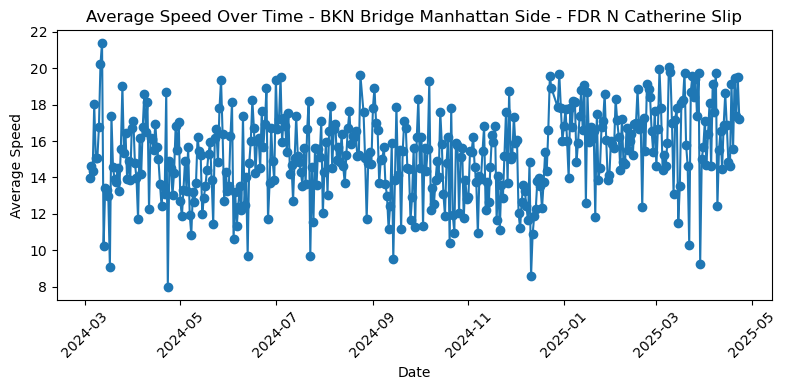

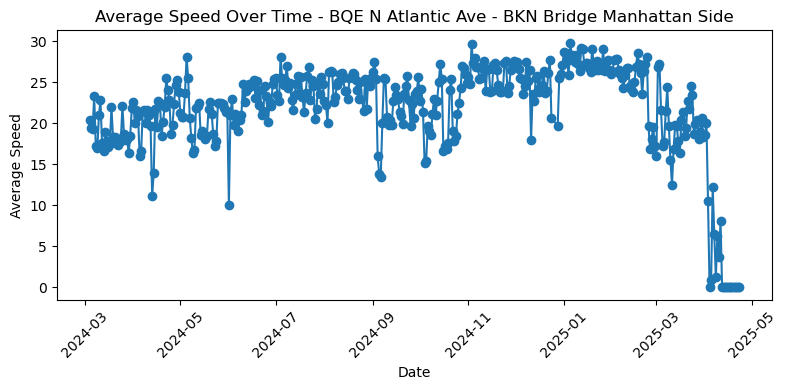

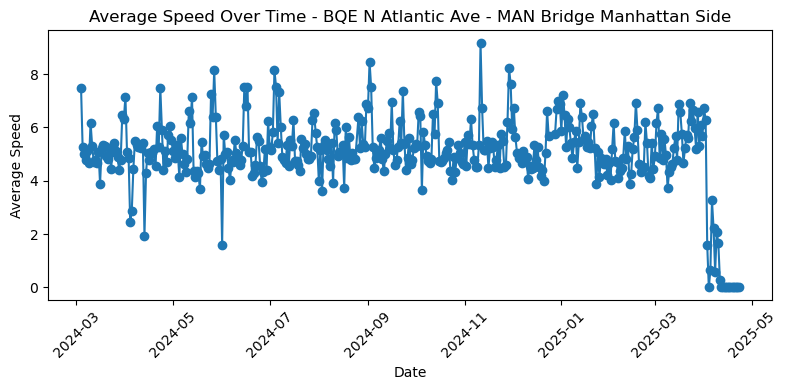

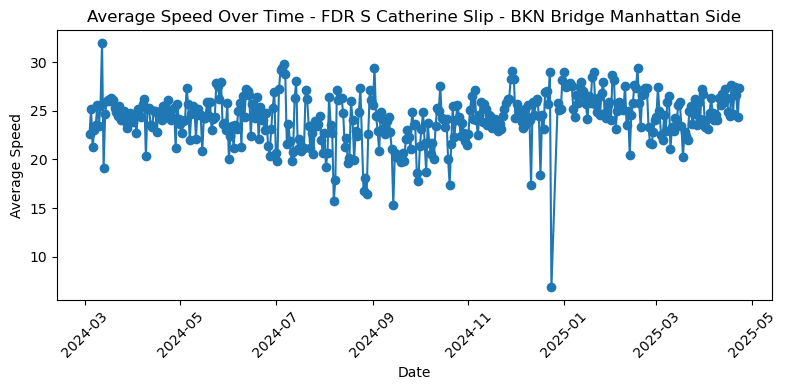

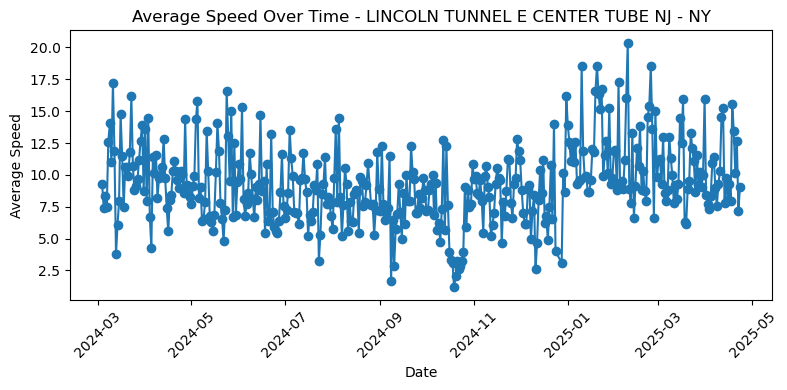

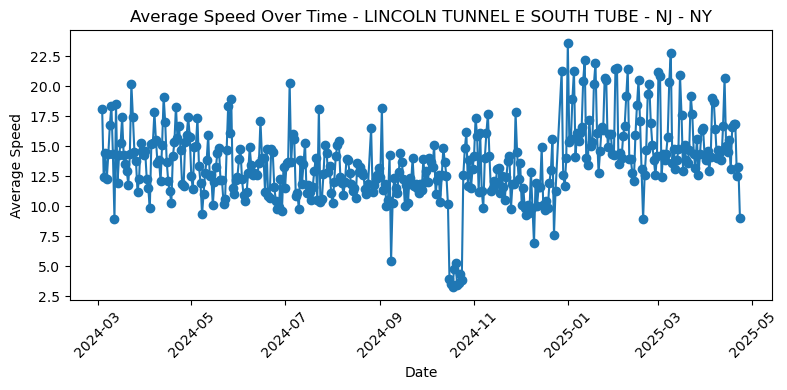

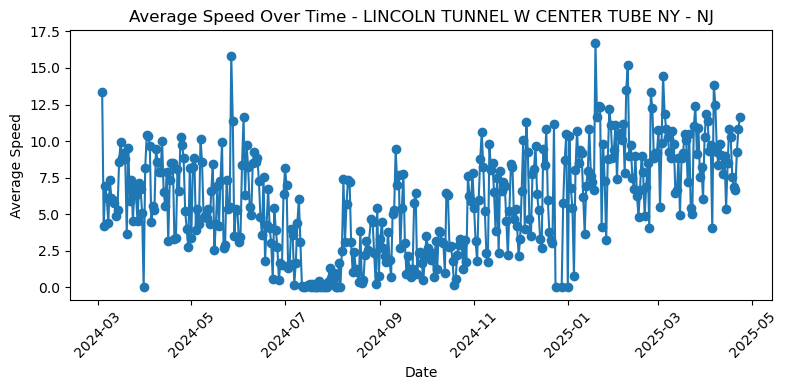

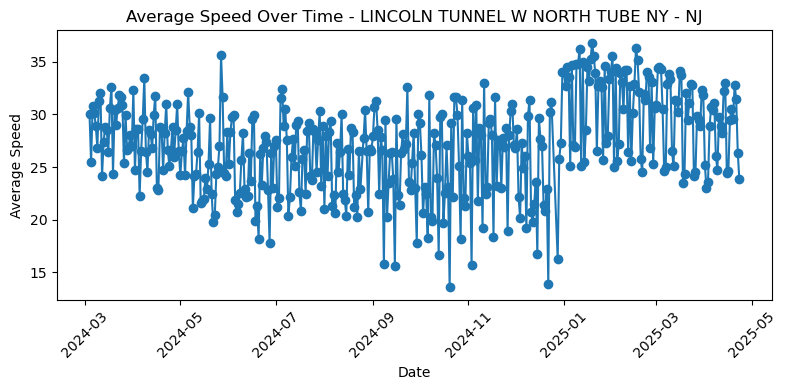

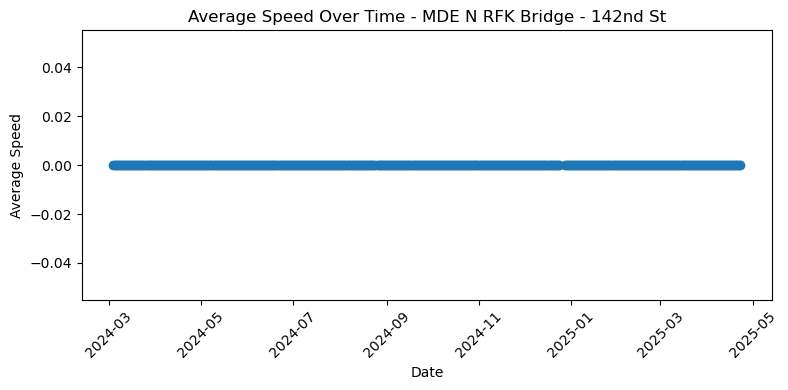

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# dfcrz = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_CRZV") # Number of vehicles that enter through each detection group a day

# dfcrz['Toll Date'] = pd.to_datetime(dfcrz['Toll Date'])
# dfcrz['Detection Group'] = dfcrz['Detection Group'].astype(str)

# entries = dfcrz.groupby([dfcrz['Detection Group'], 
#                          dfcrz['Toll Date'].dt.date])[['CRZ Entries','Excluded Roadway Entries']].sum().reset_index()

# entries.columns = ['Detection Group', 'Toll Date', 'CRZ Entries', 'Excluded Roadway Entries']
# entries['Toll Date'] = pd.to_datetime(entries['Toll Date'])

# bt = entries['Detection Group'].unique()
# btnum = len(bt)

# fig, axes = plt.subplots(btnum, 1, figsize=(10, 4 * btnum), sharex=False)

# for i, bridge in enumerate(bt):
#     bt_data = entries[entries['Detection Group'] == bridge]
#     axes[i].plot(bt_data['Toll Date'], bt_data['CRZ Entries'], marker='o')
#     axes[i].set_title(f"CRZ Entries Over Time - Group {bridge}")
#     axes[i].set_xlabel("Toll Date")
#     axes[i].set_ylabel("Entries")
#     axes[i].tick_params(axis='x', rotation=45)
# plt.tight_layout()
# plt.show()

# def switch(p):
#     if p == "TBX":
#         return "Robert F. Kennedy Bridge Bronx Plaza and Queens Plaza"
#     elif p == "TBM":
#         return "Robert F. Kennedy Bridge Manhattan Plaza "
#     elif p == "BWB":
#         return "Bronx-Whitestone Bridge"
#     elif p == "HHB":
#         return " Henry Hudson Bridge"
#     elif p == "MPB":
#         return "Marine Parkway-Gil Hodges Memorial Bridge"
#     elif p == "CBB":
#         return " Cross Bay Veterans Memorial Bridge"
#     elif p == "QMT":
#         return " Queens Midtown Tunnel "
#     elif p == "HCT":
#         return " Hugh L. Carey Tunnel"
#     elif p == "TNB":
#         return "Throgs Neck Bridge"
#     elif p == "VNB":
#         return "Verrazano-Narrows Bridge"
# df2 = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_BT") # Number of entries through buses and tunnels for 2024 and 2025

# bt_Totals = {}

# for index, row in df2.iterrows():
#     btdate = row['Date']
#     plaza= row['Plaza ID']
#     btEntries = row['# Vehicles - E-ZPass'] + row['# Vehicles - VToll']

#     if btdate not in bt_Totals :
#         bt_Totals[btdate] = {}
#     if plaza in bt_Totals[btdate]:
#         bt_Totals[btdate][plaza] += btEntries
#     else:
#         bt_Totals[btdate][plaza] = btEntries  

# dfbt = pd.DataFrame(bt_Totals).T 
# dfbt.index = pd.to_datetime(dfbt.index)
# dfbt = dfbt.sort_index()

# pza = dfbt.columns
# pza_num = len(pza)

# fig, axes = plt.subplots(pza_num, 1, figsize=(12, 4 * pza_num), sharex=True)

# for i, plaza in enumerate(pza):
#     axes[i].plot(dfbt.index, dfbt[plaza], marker='o')
#     axes[i].set_title(f"Vehicle Entries Over Time at - {switch(plaza)}")
#     axes[i].set_ylabel("Entries")
#     axes[i].tick_params(axis='x', rotation=45)

# axes[-1].set_xlabel("Date")
# plt.tight_layout()
# plt.show()

# df3 = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_Rides_2024") # Dataframe for 2024 subway rides

# preCRZ_Totals = {}

# for index, row in df3.iterrows():
#     predate = row['Date']
#     presubways= row['Subways']
#     preCRZ_Totals[predate] = {'Subways': presubways}
    
# df3 = pd.DataFrame(preCRZ_Totals).T 
# df3.index = pd.to_datetime(df3.index)
# df3 = df3.sort_index()

# plt.figure(figsize=(20,10))
# plt.ylim(0, 5000000)
# plt.xlim(pd.to_datetime("2024-01-01"), pd.to_datetime("2024-12-31"))
# plt.plot(df3.index, df3['Subways'], marker='o', label='Subways')
# plt.title(f"Subway Ridership 2024")
# plt.xlabel("Date (For the past year)")
# plt.ylabel("Rides (in millions)")
# plt.tick_params(axis='x', rotation=45)
# plt.show()


# df4 = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_Station_Rides_2025")
# ways = ['2','3','6','7','A','B','C','D','E','F','J','L','M','N','Q','R','W']
# postCRZ_subways = {}

# for index, row in df4.iterrows():
#     subdate = pd.to_datetime(row['Date']).date() 
#     rides = float(row['Estimated Average Ridership'])
#     station =str(row['Station Name'])
#     raw_lines = re.findall(r'\((.*?)\)', station)
#     lines = []
    
#     for group in raw_lines:
#         parts = group.split(',')
#         lines.extend([p.strip() for p in parts])
        
#     if any(x in ways for x in lines):
#         if subdate in postCRZ_subways:
#             postCRZ_subways[subdate] += rides
#         else:
#             postCRZ_subways[subdate] = rides
        
# dfsub = pd.DataFrame(list(postCRZ_subways.items()), columns=['Date', 'Avg Rides'])
# dfsub['Date'] = pd.to_datetime(dfsub['Date'])
# dfsub = dfsub.sort_values('Date')
# plt.figure(figsize=(12, 6))
# plt.plot(dfsub['Date'], dfsub['Avg Rides'], marker='o')
# plt.ylim(0,2000000)
# plt.title("Subway Ridership by Date")
# plt.xlabel("Date")
# plt.ylabel("Ridership (in millions)")
# plt.grid(True)
# plt.tight_layout()
# plt.xticks(rotation=45)
# plt.show()

dfstreets = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "Speed_CRZs") # Each graph will be for a specific link. Date for x and speed for y

dfstreets['DATA_AS_OF'] = pd.to_datetime(dfstreets['DATA_AS_OF'])
dfstreets['LINK_NAME'] = dfstreets['LINK_NAME'].astype(str)
avg_speed = dfstreets.groupby([dfstreets['LINK_NAME'], dfstreets['DATA_AS_OF'].dt.date])['SPEED'].mean().reset_index()
avg_speed.columns = ['Street', 'Date', 'Average_Speed']
heatmap_data = avg_speed.pivot(index='Street', columns='Date', values='Average_Speed')

for street in avg_speed['Street'].unique():
    speed = avg_speed[avg_speed['Street'] == street]

    plt.figure(figsize=(8, 4))
    plt.plot(pd.to_datetime(speed['Date']), speed['Average_Speed'], marker='o')
    plt.title(f"Average Speed Over Time - {street}")
    plt.xlabel("Date")
    plt.ylabel("Average Speed")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()